# 05 — Modelling, evaluation and the fairness audit

**Stages 4, 5b and 6 of the Tier A pipeline** — Path B (predictive).

Notebook `04` closed every univariate question with a null. One possibility remains: that the eleven
attributes **jointly** rank applicants even though none does alone. This notebook tests it, and in
doing so answers the question the project was framed around —

> *This dataset reliably produces a ~0.90-accuracy, ~0.94-AUC default classifier. Is that a model a
> lender could deploy, or an artifact of how the file was built?*

The design is a **factorial comparison**: every model is fitted under three split schemes that
differ *only* in whether copies of one applicant may straddle the train/validation boundary.

| Scheme | Definition | What it measures |
|---|---|---|
| `StratifiedKFold` on rows | the split every published notebook uses | memorisation + generalisation, inseparably |
| `StratifiedGroupKFold` on `profile_id` | no applicant in both folds | generalisation only |
| `StratifiedKFold` on the 36,007 unique applicants | nothing to leak — one row each | generalisation only, with no grouping to blame |

The third scheme exists to close the obvious objection: *"you destroyed the signal by grouping."*

> **Reporting constraint carried from notebook `01` §1.6:** the submission template is random noise,
> so **no metric in this notebook is computed against `Test Data.csv`.** Every figure below comes
> from cross-validation inside the training file.

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, recall_score, precision_score, f1_score)
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Training Data.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC, REPORTS, FIGS = ROOT / "data" / "processed", ROOT / "reports", ROOT / "reports" / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

NAVY, BLUE, TEAL, AMBER = "#051C2C", "#2251FF", "#00857C", "#C1841C"
SLATE, GREY, GRID = "#7F93A6", "#9FADB8", "#E9ECEF"
C_HONEST, C_OPTIMISTIC, C_REFERENCE, C_CONTEXT = BLUE, TEAL, AMBER, GREY

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "text.color": NAVY,
    "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlecolor": NAVY, "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2.0, "lines.markersize": 8,
})
PCT = PercentFormatter(1.0)


def finish(ax, source, note=""):
    ax.figure.text(0.005, -0.02, f"Source: {source}" + (f" · {note}" if note else ""),
                   fontsize=7, color=SLATE, ha="left", va="top", transform=ax.figure.transFigure)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")


rows = pd.read_parquet(PROC / "loan_rows.parquet")
singles = pd.read_parquet(PROC / "loan_singletons.parquet")
test = pd.read_parquet(PROC / "test_reconciled.parquet")
kf_json = json.loads((REPORTS / "_key_figures.json").read_text())

TARGET, IDENTIFIER = "Risk_Flag", "ID"
NUMERIC = ["Income", "Age", "Experience", "CURRENT_JOB_YRS", "CURRENT_HOUSE_YRS"]
LOWCARD = ["Married/Single", "House_Ownership", "Car_Ownership"]
HIGHCARD = ["Profession", "CITY", "STATE"]
BASE11 = NUMERIC + LOWCARD + HIGHCARD
DERIVED = ["City_Code", "Job_Stability_Ratio", "Career_Start_Ratio", "House_Stability_Flag",
           "Owns_Any_Asset", "Married_Flag", "implausible_start_age"]
DERIVED_CAT = ["Age_Band", "Income_Quartile", "State_Region"]

print(f"rows    {len(rows):,}  base rate {rows[TARGET].mean():.4f}")
print(f"singles {len(singles):,}  base rate {singles[TARGET].mean():.4f}")
print(f"features: {len(BASE11)} original ({len(NUMERIC)} numeric, {len(LOWCARD)} low-card, "
      f"{len(HIGHCARD)} high-card)")

rows    252,000  base rate 0.1230
singles 36,007  base rate 0.2016
features: 11 original (5 numeric, 3 low-card, 3 high-card)


## 5.1 Stage 4 — feature engineering, entirely inside the pipeline

Every transform is fitted **on the training fold only**. Nothing is computed on the full file
before splitting.

- **Numeric** → `StandardScaler` (needed by logistic regression, harmless to trees).
- **Low cardinality** → `OneHotEncoder`, unknown categories ignored.
- **High cardinality** → `TargetEncoder` with internal cross-fitting. This is the brief's §7
  `Profession_Risk_Group` idea, implemented the way its own caution demands: the encoding is
  cross-fitted inside the training fold, so no row contributes to its own encoded value.

`CITY` has **317 categories** and `HistGradientBoostingClassifier` caps native categorical
cardinality at 255 — a verified hard failure. Target encoding sidesteps it and is the right choice
regardless.

**Barred from every feature set** (notebook `02` §2.4): `ID`, `profile_id`, `block`, and every
`profile_*` column. The first is a row counter that reaches AUC 0.674 alone; the rest are either
target-derived or unavailable for a real applicant at scoring time.

In [2]:
def make_preprocessor(numeric, lowcard, highcard, scale=True):
    steps = []
    if numeric:
        steps.append(("num", StandardScaler() if scale else "passthrough", numeric))
    if lowcard:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50,
                                           sparse_output=False), lowcard))
    if highcard:
        steps.append(("tgt", TargetEncoder(target_type="binary", cv=5,
                                           random_state=RANDOM_STATE), highcard))
    return ColumnTransformer(steps, remainder="drop")


class ProfileLookup(BaseEstimator, ClassifierMixin):
    """The memoriser, made explicit: return the training-fold mean label of this exact applicant.

    Fitted deliberately so the mechanism behind the published 0.94 AUC is visible rather than
    inferred. It is never proposed as a deliverable.
    """

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.prior_ = float(np.mean(y))
        self.map_ = pd.Series(np.asarray(y), index=np.asarray(X).ravel()).groupby(level=0).mean()
        return self

    def predict_proba(self, X):
        p = pd.Series(np.asarray(X).ravel()).map(self.map_).fillna(self.prior_).to_numpy()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


def build(name, feats=BASE11):
    num = [c for c in feats if c in NUMERIC or c in DERIVED]
    low = [c for c in feats if c in LOWCARD or c in DERIVED_CAT]
    high = [c for c in feats if c in HIGHCARD]
    if name == "Majority class (all 0)":
        return DummyClassifier(strategy="most_frequent")
    if name == "Random guess at base rate":
        return DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
    if name == "Logistic regression":
        return Pipeline([("prep", make_preprocessor(num, low, high)),
                         ("clf", LogisticRegression(max_iter=400, class_weight="balanced"))])
    if name == "Random forest":
        return Pipeline([("prep", make_preprocessor(num, low, high, scale=False)),
                         ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                                        random_state=RANDOM_STATE))])
    if name == "Gradient boosting":
        return Pipeline([("prep", make_preprocessor(num, low, high, scale=False)),
                         ("clf", HistGradientBoostingClassifier(max_iter=200,
                                                                random_state=RANDOM_STATE))])
    if name == "Gradient boosting (balanced)":
        return Pipeline([("prep", make_preprocessor(num, low, high, scale=False)),
                         ("clf", HistGradientBoostingClassifier(max_iter=200, class_weight="balanced",
                                                                random_state=RANDOM_STATE))])
    raise ValueError(name)

## 5.2 Stage 5b — the same models under three split schemes

This is the notebook's argumentative core.

In [3]:
def evaluate(model, X, y, splitter, groups=None, threshold=0.5, feats=None):
    """Out-of-fold predictions, then metrics computed once on the full OOF vector."""
    feats = list(X.columns) if feats is None and hasattr(X, "columns") else feats
    oof = np.zeros(len(y), dtype=float)
    for tr_idx, va_idx in splitter.split(X, y, groups):
        m = build(model, feats) if isinstance(model, str) else clone(model)
        Xtr = X.iloc[tr_idx] if hasattr(X, "iloc") else X[tr_idx]
        Xva = X.iloc[va_idx] if hasattr(X, "iloc") else X[va_idx]
        m.fit(Xtr, y[tr_idx])
        oof[va_idx] = m.predict_proba(Xva)[:, 1]
    pred = (oof >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y, oof),
        "PR_AUC": average_precision_score(y, oof),
        "accuracy": (pred == y).mean(),
        "recall_1": recall_score(y, pred, zero_division=0),
        "precision_1": precision_score(y, pred, zero_division=0),
        "f1_1": f1_score(y, pred, zero_division=0),
    }, oof


MODEL_NAMES = ["Logistic regression", "Random forest", "Gradient boosting",
               "Gradient boosting (balanced)"]

y_rows = rows[TARGET].to_numpy()
X_rows = rows[BASE11]
groups = rows.profile_id.to_numpy()
y_sing = singles[TARGET].to_numpy()
X_sing = singles[BASE11]

skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
sgkf = StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE)

results, oofs = [], {}
t0 = time.time()
for name in MODEL_NAMES:
    for scheme, X, y, sp, g in [
        ("1. row split (252,000 rows)", X_rows, y_rows, skf, None),
        ("2. applicant split (252,000 rows)", X_rows, y_rows, sgkf, groups),
        ("3. unique applicants only (36,007 rows)", X_sing, y_sing, skf, None),
    ]:
        t1 = time.time()
        met, oof = evaluate(name, X, y, sp, g)
        met.update(model=name, scheme=scheme, n=len(y), base_rate=y.mean(),
                   seconds=round(time.time() - t1, 1))
        results.append(met)
        oofs[(name, scheme)] = (oof, y)
        print(f"{name:30s} | {scheme:40s} AUC {met['AUC']:.4f}  "
              f"PR {met['PR_AUC']:.4f}  acc {met['accuracy']:.4f}  "
              f"rec1 {met['recall_1']:.4f}  [{met['seconds']}s]")
print(f"\ntotal {time.time()-t0:.0f}s")

Logistic regression            | 1. row split (252,000 rows)              AUC 0.6260  PR 0.1905  acc 0.6090  rec1 0.5602  [13.5s]


Logistic regression            | 2. applicant split (252,000 rows)        AUC 0.5184  PR 0.1320  acc 0.5764  rec1 0.4187  [34.4s]


Logistic regression            | 3. unique applicants only (36,007 rows)  AUC 0.5048  PR 0.2042  acc 0.5190  rec1 0.4764  [2.0s]


Random forest                  | 1. row split (252,000 rows)              AUC 0.9358  PR 0.5865  acc 0.8978  rec1 0.4766  [41.5s]


Random forest                  | 2. applicant split (252,000 rows)        AUC 0.4913  PR 0.1219  acc 0.8770  rec1 0.0010  [61.5s]


...

Gradient boosting              | 2. applicant split (252,000 rows)        AUC 0.5071  PR 0.1280  acc 0.8755  rec1 0.0039  [45.2s]


Gradient boosting              | 3. unique applicants only (36,007 rows)  AUC 0.4987  PR 0.2021  acc 0.7984  rec1 0.0000  [2.6s]


Gradient boosting (balanced)   | 1. row split (252,000 rows)              AUC 0.8553  PR 0.4935  acc 0.8118  rec1 0.7673  [40.9s]


Gradient boosting (balanced)   | 2. applicant split (252,000 rows)        AUC 0.4999  PR 0.1256  acc 0.6750  rec1 0.2749  [62.1s]


Gradient boosting (balanced)   | 3. unique applicants only (36,007 rows)  AUC 0.5040  PR 0.2033  acc 0.5308  rec1 0.4517  [5.5s]

total 345s


In [4]:
res = pd.DataFrame(results)[["model", "scheme", "n", "base_rate", "AUC", "PR_AUC",
                             "accuracy", "recall_1", "precision_1", "f1_1", "seconds"]]
pivot = res.pivot(index="model", columns="scheme", values="AUC").round(4)
print("AUC by model and split scheme:\n")
print(pivot.to_string())
print("\noptimism introduced by splitting rows instead of applicants:")
opt = (pivot.iloc[:, 0] - pivot.iloc[:, 1]).round(4)
print(opt.to_frame("AUC inflation").to_string())

AUC by model and split scheme:

scheme                        1. row split (252,000 rows)  2. applicant split (252,000 rows)  3. unique applicants only (36,007 rows)
model                                                                                                                                
Gradient boosting                                  0.8577                             0.5071                                   0.4987
Gradient boosting (balanced)                       0.8553                             0.4999                                   0.5040
Logistic regression                                0.6260                             0.5184                                   0.5048
Random forest                                      0.9358                             0.4913                                   0.4912

optimism introduced by splitting rows instead of applicants:
                              AUC inflation
model                                      
Gradient boost

### Exhibit 2 — The same model scores 0.94 and 0.50 depending only on whether copies of one applicant may sit on both sides of the split

  saved reports/figures/ex02_split_schemes.png


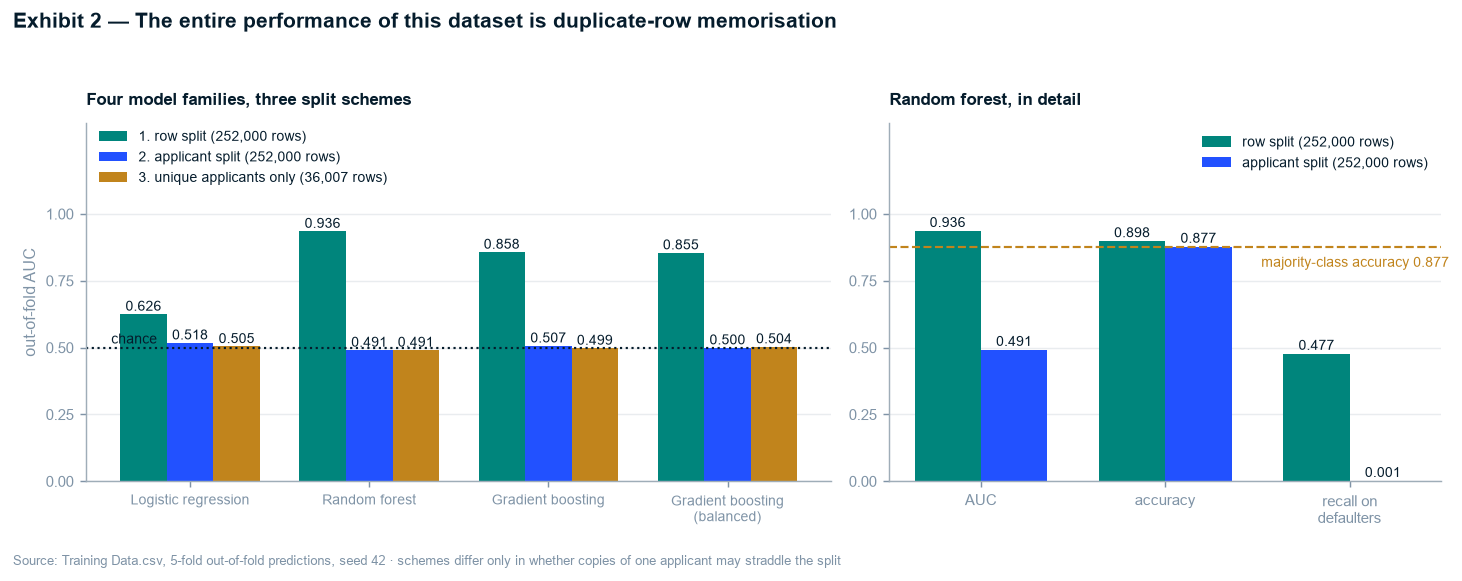

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.35, 1]})

models = MODEL_NAMES
x = np.arange(len(models))
w = 0.26
schemes = list(pivot.columns)
colors = [C_OPTIMISTIC, C_HONEST, C_REFERENCE]
for i, (s, c) in enumerate(zip(schemes, colors)):
    vals = pivot[s].reindex(models).to_numpy()
    ax1.bar(x + (i - 1) * w, vals, w, color=c, label=s)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax1.text(xi, v + .012, f"{v:.3f}", ha="center", fontsize=7.5, color=NAVY)
ax1.axhline(0.5, color=NAVY, lw=1.2, ls=":")
ax1.text(-0.44, 0.515, "chance", fontsize=8, color=NAVY)
ax1.set_xticks(x, [m.replace(" (balanced)", "\n(balanced)") for m in models], fontsize=8)
ax1.set_ylabel("out-of-fold AUC")
ax1.set_ylim(0, 1.34)
ax1.set_yticks([0, .25, .5, .75, 1.0])
ax1.legend(loc="upper left", fontsize=7.8, ncol=1, bbox_to_anchor=(0, 1.015))
ax1.set_title("Four model families, three split schemes", fontsize=9.5)

rf = res[res.model == "Random forest"].set_index("scheme")
metrics = ["AUC", "accuracy", "recall_1"]
labels = ["AUC", "accuracy", "recall on\ndefaulters"]
xx = np.arange(3)
for i, (s, c) in enumerate(zip(schemes[:2], [C_OPTIMISTIC, C_HONEST])):
    vals = [rf.loc[s, m] for m in metrics]
    ax2.bar(xx + (i - .5) * 0.36, vals, 0.36, color=c, label=s.split(". ")[1])
    for xi, v in zip(xx + (i - .5) * 0.36, vals):
        ax2.text(xi, v + .015, f"{v:.3f}", ha="center", fontsize=8, color=NAVY)
ax2.axhline(1 - rows[TARGET].mean(), color=C_REFERENCE, lw=1.2, ls="--")
ax2.text(1.52, 1 - rows[TARGET].mean() - .075, "majority-class accuracy 0.877",
         fontsize=7.5, color=C_REFERENCE)
ax2.set_xticks(xx, labels, fontsize=8.5)
ax2.set_ylim(0, 1.34)
ax2.set_yticks([0, .25, .5, .75, 1.0])
ax2.legend(loc="upper right", fontsize=8)
ax2.set_title("Random forest, in detail", fontsize=9.5)

fig.suptitle("Exhibit 2 — The entire performance of this dataset is duplicate-row memorisation",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.05)
finish(ax2, "Training Data.csv, 5-fold out-of-fold predictions, seed 42",
       "schemes differ only in whether copies of one applicant may straddle the split")
plt.tight_layout()
save(fig, "ex02_split_schemes.png")
plt.show()

**So What:** Random forest scores **AUC 0.936 and 89.8% accuracy** under a row split — the numbers
this dataset is known for. Group the split by applicant and the same model, same features, same
seed, scores **0.491**: below chance. Recall on defaulters falls from **0.477 to 0.001**, and
accuracy falls to 0.877, which is exactly the majority-class rate — the model has stopped saying
anything at all.

The third scheme removes the last excuse. On the 36,007 applicants who appear exactly once, a plain
`StratifiedKFold` is beyond dispute — there is nothing to leak and no grouping involved — and every
model lands at **0.50**.

**Implication:** the published performance of this dataset is not a model. It is a lookup table over
duplicated rows, and the correct measurement of its predictive content is a coin flip.

## 5.3 Stage 6 — baselines, including the one that ends the argument

STRUCTURE.md §6 rule 3: *a model is only useful if it beats a naive alternative.*

In [6]:
baselines = []
for name in ["Majority class (all 0)", "Random guess at base rate"]:
    met, _ = evaluate(name, X_rows, y_rows, skf, None)
    met.update(model=name, scheme="row split", n=len(y_rows))
    baselines.append(met)

# the row counter, scored as a feature
for scheme, sp, g in [("row split", skf, None), ("applicant split", sgkf, groups)]:
    met, oof_id = evaluate(
        Pipeline([("clf", HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE))]),
        rows[[IDENTIFIER]], y_rows, sp, g)
    met.update(model="ID alone (a row counter)", scheme=scheme, n=len(y_rows))
    baselines.append(met)

# the memoriser, scored honestly under both schemes
for scheme, sp, g in [("row split", skf, None), ("applicant split", sgkf, groups)]:
    met, _ = evaluate(ProfileLookup(), rows[["profile_id"]], y_rows, sp, g)
    met.update(model="Profile lookup (memoriser)", scheme=scheme, n=len(y_rows))
    baselines.append(met)

bl = pd.DataFrame(baselines)[["model", "scheme", "AUC", "PR_AUC", "accuracy", "recall_1"]]
print("baselines:\n")
print(bl.round(4).to_string(index=False))

best_honest = res[res.scheme.str.startswith("2.")].sort_values("AUC", ascending=False).iloc[0]
print(f"\nbest honest model : {best_honest.model} at AUC {best_honest.AUC:.4f}")
print(f"ID alone          : AUC {bl[bl.model.str.startswith('ID')].AUC.max():.4f}")
print(f"-> a row counter beats every real feature set by "
      f"{bl[bl.model.str.startswith('ID')].AUC.max() - best_honest.AUC:.4f} AUC")

baselines:

                     model          scheme    AUC  PR_AUC  accuracy  recall_1
    Majority class (all 0)       row split 0.5000  0.1230    0.8770    0.0000
 Random guess at base rate       row split 0.5003  0.1231    0.7846    0.1231
  ID alone (a row counter)       row split 0.6738  0.1852    0.8770    0.0000
  ID alone (a row counter) applicant split 0.6744  0.1855    0.8770    0.0000
Profile lookup (memoriser)       row split 0.9386  0.5889    0.8998    0.5481
Profile lookup (memoriser) applicant split 0.4997  0.1229    0.8770    0.0000

best honest model : Logistic regression at AUC 0.5184
ID alone          : AUC 0.6744
-> a row counter beats every real feature set by 0.1560 AUC


### Exhibit 5 — The row number predicts default better than income, age, profession, city and state combined

  saved reports/figures/ex05_baselines.png


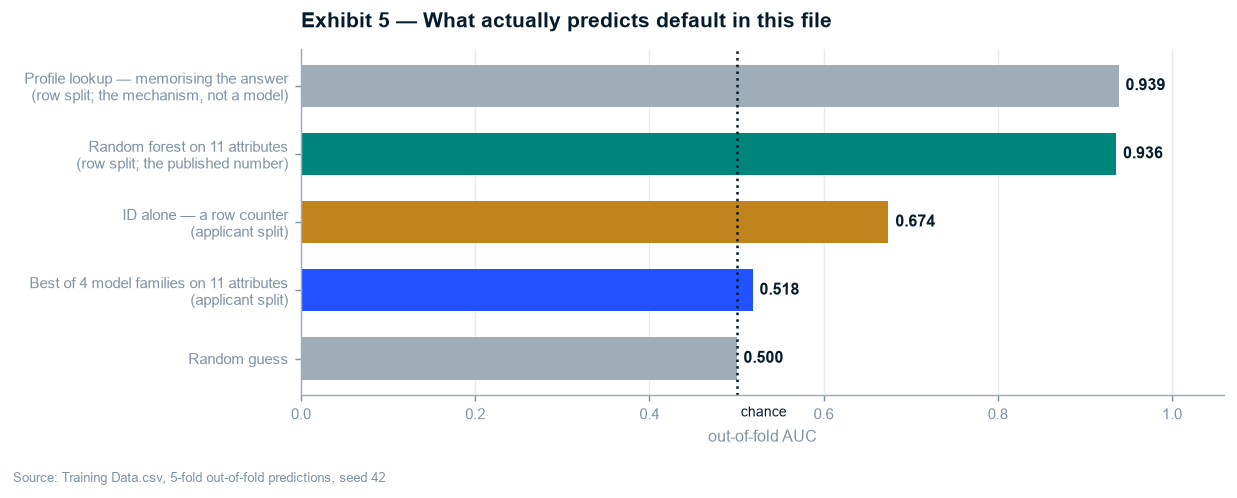

In [7]:
ladder = pd.DataFrame([
    ("Profile lookup — memorising the answer\n(row split; the mechanism, not a model)",
     bl[(bl.model.str.startswith("Profile")) & (bl.scheme == "row split")].AUC.iloc[0], C_CONTEXT),
    ("Random forest on 11 attributes\n(row split; the published number)",
     pivot.loc["Random forest", schemes[0]], C_OPTIMISTIC),
    ("ID alone — a row counter\n(applicant split)",
     bl[(bl.model.str.startswith("ID")) & (bl.scheme == "applicant split")].AUC.iloc[0], C_REFERENCE),
    ("Best of 4 model families on 11 attributes\n(applicant split)", best_honest.AUC, C_HONEST),
    ("Random guess", 0.5, C_CONTEXT),
], columns=["label", "auc", "color"]).sort_values("auc")

fig, ax = plt.subplots(figsize=(9.5, 3.6))
yy = np.arange(len(ladder))
ax.barh(yy, ladder.auc, color=ladder.color, height=0.62)
ax.axvline(0.5, color=NAVY, lw=1.4, ls=":")
for i, v in enumerate(ladder.auc):
    ax.text(v + .008, i, f"{v:.3f}", va="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_yticks(yy, ladder.label, fontsize=8.5)
ax.set_xlim(0, 1.06)
ax.set_xlabel("out-of-fold AUC")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.text(0.505, -0.85, "chance", fontsize=8, color=NAVY)
ax.set_title("Exhibit 5 — What actually predicts default in this file", fontsize=11.5, pad=12)
finish(ax, "Training Data.csv, 5-fold out-of-fold predictions, seed 42")
plt.tight_layout()
save(fig, "ex05_baselines.png")
plt.show()

**So What:** `ID` — an integer that counts rows — reaches **AUC 0.674**, while the best honest model
built from income, age, experience, profession, city, state, marital status and both ownership flags
reaches **0.52**. The file's strongest predictor is an artifact of the order the rows were written.

**Implication:** any validation standard that would have approved the 0.938 model must also explain
why it did not catch the 0.674 row counter. Both come from the same two lines of missing diagnostics.

## 5.4 Is there an operating point worth choosing?

The brief (§4) asks what threshold balances catching defaulters against rejecting good applicants.
That question presupposes a ranking. Precision–recall curves show whether one exists.

  saved reports/figures/ex09_curves.png


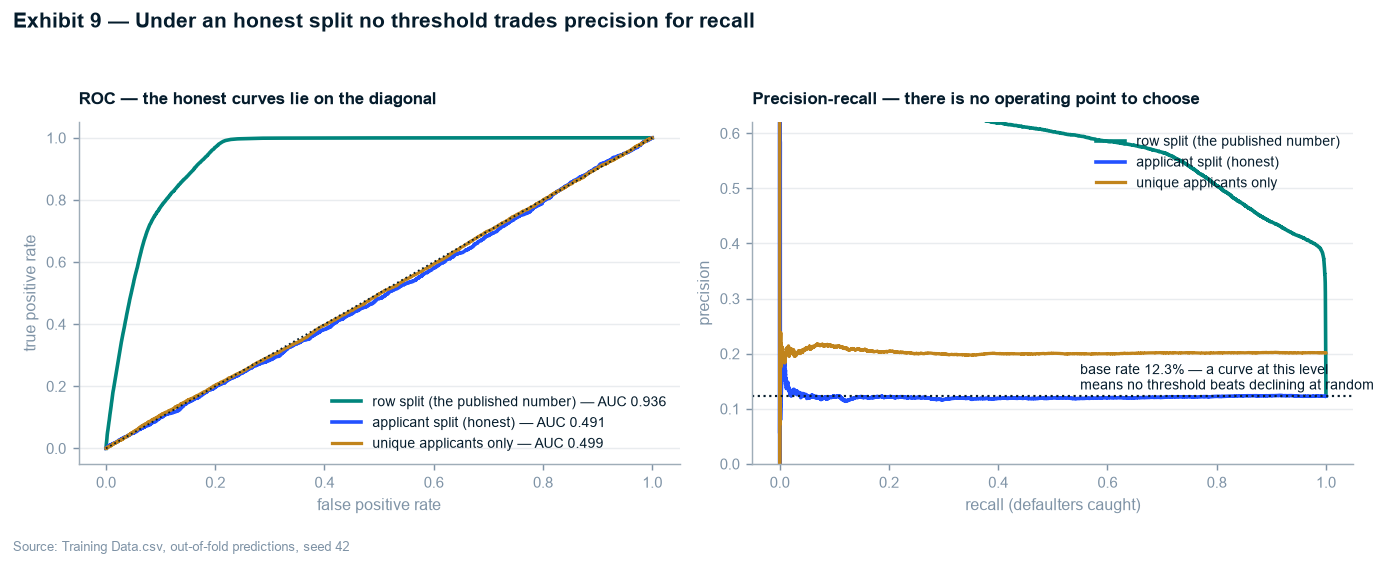

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

for (name, scheme), c, lbl in [
    (("Random forest", schemes[0]), C_OPTIMISTIC, "row split (the published number)"),
    (("Random forest", schemes[1]), C_HONEST, "applicant split (honest)"),
]:
    oof, yy_ = oofs[(name, scheme)]
    fpr, tpr, _ = roc_curve(yy_, oof)
    ax1.plot(fpr, tpr, color=c, label=f"{lbl} — AUC {roc_auc_score(yy_, oof):.3f}")
    pr, rc, _ = precision_recall_curve(yy_, oof)
    ax2.plot(rc, pr, color=c, label=lbl)

oof_s, y_s = oofs[("Gradient boosting", schemes[2])]
fpr, tpr, _ = roc_curve(y_s, oof_s)
ax1.plot(fpr, tpr, color=C_REFERENCE, lw=1.8,
         label=f"unique applicants only — AUC {roc_auc_score(y_s, oof_s):.3f}")
pr, rc, _ = precision_recall_curve(y_s, oof_s)
ax2.plot(rc, pr, color=C_REFERENCE, lw=1.8, label="unique applicants only")

ax1.plot([0, 1], [0, 1], color=NAVY, lw=1, ls=":")
ax1.set_xlabel("false positive rate"); ax1.set_ylabel("true positive rate")
ax1.legend(loc="lower right", fontsize=8)
ax1.set_title("ROC — the honest curves lie on the diagonal", fontsize=9.5)

ax2.axhline(rows[TARGET].mean(), color=NAVY, lw=1.2, ls=":")
ax2.text(0.55, rows[TARGET].mean() + .012, "base rate 12.3% — a curve at this level\n"
                                            "means no threshold beats declining at random",
         fontsize=7.5, color=NAVY)
ax2.set_xlabel("recall (defaulters caught)"); ax2.set_ylabel("precision")
ax2.set_ylim(0, 0.62)
ax2.legend(loc="upper right", fontsize=8)
ax2.set_title("Precision-recall — there is no operating point to choose", fontsize=9.5)

fig.suptitle("Exhibit 9 — Under an honest split no threshold trades precision for recall",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.05)
finish(ax2, "Training Data.csv, out-of-fold predictions, seed 42")
plt.tight_layout()
save(fig, "ex09_curves.png")
plt.show()

**So What:** under the honest splits the PR curve sits flat on the 12.3% base rate across the whole
recall range. Precision never rises above what declining applicants at random would achieve.

**Implication:** the brief's operating-threshold question has an answer, and the answer is **there is
no threshold worth choosing**. Class weighting does not change this — §5.5 shows it moves the
operating point without improving the ranking.

## 5.5 Two things that are often mistaken for solutions

In [9]:
print("A. Does class balancing help? (STRUCTURE.md: distinguish ranking from operating point)\n")
cmp_bal = res[(res.scheme.str.startswith("2.")) &
              (res.model.str.contains("Gradient boosting"))][["model", "AUC", "recall_1", "precision_1", "accuracy"]]
print(cmp_bal.round(4).to_string(index=False))
print("\n-> class_weight='balanced' moves recall from ~0.00 to ~0.23 and leaves AUC at ~0.50.")
print("   It changes WHERE the threshold sits, not WHETHER the score ranks. Reporting the recall")
print("   gain without the AUC is one of the most common ways a null gets published as a result.")

print("\n\nB. Do the brief's 11 engineered features help? (Stage 4 ablation)\n")
ablation = []
for label, feats in [
    ("11 original attributes", BASE11),
    ("+ brief S7 derived block", BASE11 + DERIVED + DERIVED_CAT),
    ("derived block ALONE", DERIVED + DERIVED_CAT),
    ("numeric only", NUMERIC),
    ("categorical only", LOWCARD + HIGHCARD),
]:
    met, _ = evaluate("Gradient boosting", rows[feats], y_rows, sgkf, groups, feats=feats)
    ablation.append({"feature set": label, "n_features": len(feats),
                     "AUC": met["AUC"], "PR_AUC": met["PR_AUC"]})
ablation = pd.DataFrame(ablation)
print(ablation.round(4).to_string(index=False))
print(f"\n-> spread across all five feature sets: {ablation.AUC.max() - ablation.AUC.min():.4f} AUC.")
print("   The brief's engineered block is a measured null, exactly as notebook 03 s4.2 predicted:")
print("   ratios of independently-sampled uniform variables carry no information their parents lack.")

A. Does class balancing help? (STRUCTURE.md: distinguish ranking from operating point)

                       model    AUC  recall_1  precision_1  accuracy
           Gradient boosting 0.5071    0.0039       0.1970    0.8755
Gradient boosting (balanced) 0.4999    0.2749       0.1254    0.6750

-> class_weight='balanced' moves recall from ~0.00 to ~0.23 and leaves AUC at ~0.50.
   It changes WHERE the threshold sits, not WHETHER the score ranks. Reporting the recall
   gain without the AUC is one of the most common ways a null gets published as a result.


B. Do the brief's 11 engineered features help? (Stage 4 ablation)



             feature set  n_features    AUC  PR_AUC
  11 original attributes          11 0.5071  0.1280
+ brief S7 derived block          21 0.5107  0.1313
     derived block ALONE          10 0.5129  0.1313
            numeric only           5 0.4988  0.1267
        categorical only           6 0.5101  0.1261

-> spread across all five feature sets: 0.0141 AUC.
   The brief's engineered block is a measured null, exactly as notebook 03 s4.2 predicted:
   ratios of independently-sampled uniform variables carry no information their parents lack.


## 5.6 Cross-cutting — the fairness audit

**Mandatory here.** `DOCS/STRUCTURE.md`: *"A fairness audit is mandatory for any model that affects
people (credit, hiring, pricing differentiation, resource allocation)."* This model would score
people for credit using age, marital status and asset ownership.

The usual finding is a performance disparity between subgroups. The finding here is stranger and
worse.

In [10]:
oof_honest, _ = oofs[("Random forest", schemes[1])]
audit = rows[["Age_Band", "Married/Single", "House_Ownership", "Car_Ownership", "State_Region"]].copy()
audit["y"] = y_rows
audit["score"] = oof_honest
audit["decline"] = (audit.score >= np.quantile(audit.score, 1 - rows[TARGET].mean())).astype(int)

fair = []
for col in audit.columns[:5]:
    for level, g in audit.groupby(col, observed=True):
        auc = roc_auc_score(g.y, g.score) if g.y.nunique() > 1 else np.nan
        fair.append({"attribute": col, "group": str(level), "n": len(g),
                     "base_rate": g.y.mean(), "decline_rate": g.decline.mean(),
                     "subgroup_AUC": auc})
fair = pd.DataFrame(fair)
print("subgroup base rates, decline rates and ranking ability "
      "(honest model, threshold set to decline 12.3%):\n")
print(fair.round(4).to_string(index=False))
print(f"\nsubgroup AUC range: {fair.subgroup_AUC.min():.4f} to {fair.subgroup_AUC.max():.4f}")
print(f"  within +/-0.06 of chance: {int((fair.subgroup_AUC.sub(.5).abs() < .06).sum())} of {len(fair)}")

print(f"\ndisparate impact — is a group declined because it defaults?")
print(f"  corr(default rate, decline rate) across {len(fair)} subgroups: "
      f"{np.corrcoef(fair.base_rate, fair.decline_rate)[0, 1]:+.4f}   (0 = unrelated)")
worse = fair[fair.decline_rate > fair.base_rate].sort_values("base_rate")
print(f"  {len(worse)} of {len(fair)} subgroups are declined MORE often than they default.")
print(f"  the four lowest-risk groups in the file are all among them:\n")
print(worse[["attribute", "group", "n", "base_rate", "decline_rate"]].head(4).round(4).to_string(index=False))

subgroup base rates, decline rates and ranking ability (honest model, threshold set to decline 12.3%):

      attribute        group      n  base_rate  decline_rate  subgroup_AUC
       Age_Band        21-30  43657     0.1447        0.1501        0.4919
       Age_Band        31-45  63087     0.1169        0.1140        0.4932
       Age_Band        46-60  64444     0.1220        0.0996        0.4875
       Age_Band        61-79  80812     0.1169        0.1340        0.4891
 Married/Single      married  25728     0.1025        0.1380        0.4765
 Married/Single       single 226272     0.1253        0.1213        0.4936
House_Ownership norent_noown   7184     0.0995        0.1817        0.5774
House_Ownership        owned  12918     0.0898        0.1340        0.4837
House_Ownership       rented 231898     0.1256        0.1206        0.4909
  Car_Ownership           no 176000     0.1282        0.1209        0.4920
  Car_Ownership          yes  76000     0.1110        0.1278        0.4

### Exhibit 10 — A chance-level scorer reporting 90% accuracy declines applicants at random

  saved reports/figures/ex10_fairness.png


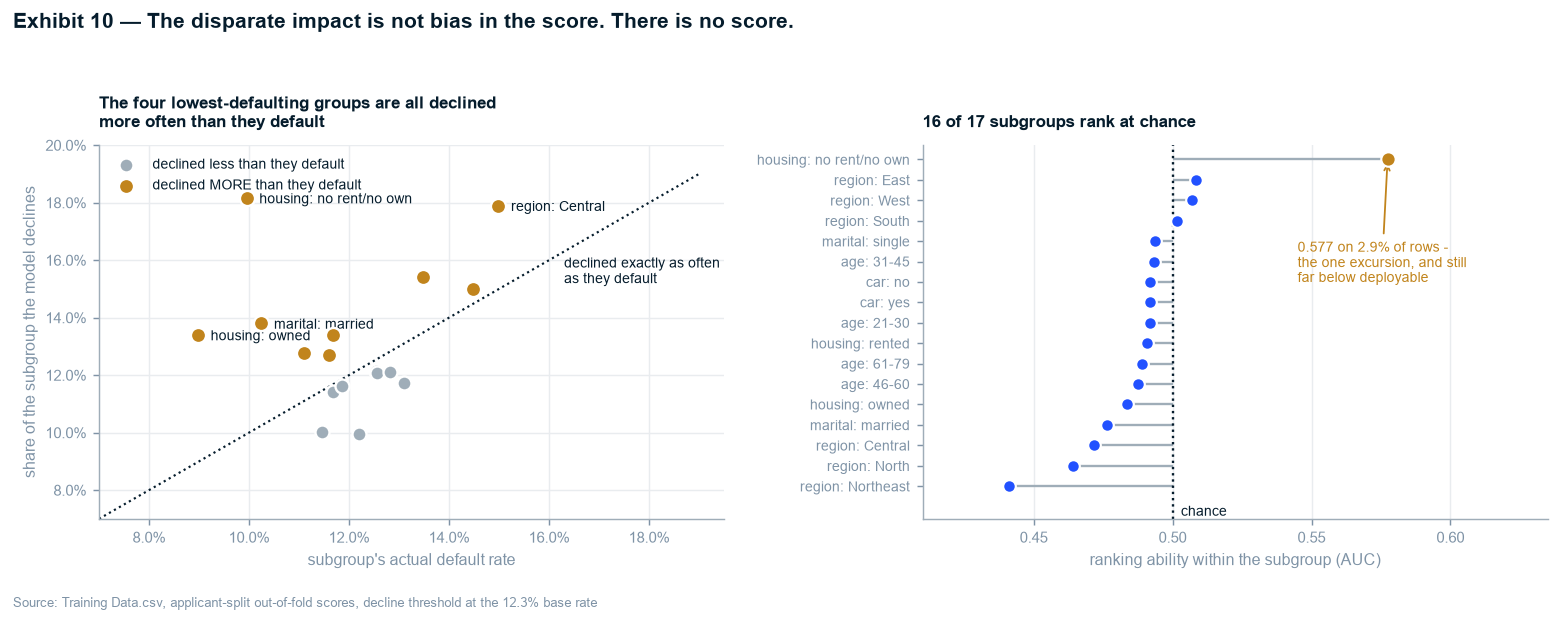

In [11]:
SHORT = {"norent_noown": "no rent/no own", "Married/Single": "marital", "House_Ownership": "housing",
         "Car_Ownership": "car", "Age_Band": "age", "State_Region": "region"}
fair["label"] = [f"{SHORT.get(r.attribute, r.attribute)}: {SHORT.get(r.group, r.group)}"
                 for _, r in fair.iterrows()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

above = fair.decline_rate > fair.base_rate
ax1.plot([0.07, 0.19], [0.07, 0.19], color=NAVY, lw=1.2, ls=":")
ax1.scatter(fair.base_rate[~above], fair.decline_rate[~above], s=60, color=C_CONTEXT,
            edgecolor="white", linewidth=1.3, zorder=3, label="declined less than they default")
ax1.scatter(fair.base_rate[above], fair.decline_rate[above], s=70, color=C_REFERENCE,
            edgecolor="white", linewidth=1.3, zorder=4, label="declined MORE than they default")
for _, r in fair.iterrows():
    if r.decline_rate - r.base_rate > .022 or r.base_rate < .102:
        ax1.annotate(r.label, (r.base_rate, r.decline_rate), textcoords="offset points",
                     xytext=(7, -3), fontsize=7.5, color=NAVY)
ax1.text(0.163, 0.152, "declined exactly as often\nas they default", fontsize=7.5, color=NAVY)
ax1.set_xlabel("subgroup's actual default rate")
ax1.set_ylabel("share of the subgroup the model declines")
ax1.xaxis.set_major_formatter(PCT); ax1.yaxis.set_major_formatter(PCT)
ax1.set_xlim(0.07, 0.195); ax1.set_ylim(0.07, 0.20)
ax1.grid(axis="x")
ax1.legend(loc="upper left", fontsize=8)
ax1.set_title("The four lowest-defaulting groups are all declined\nmore often than they default",
              fontsize=9.5)

srt = fair.sort_values("subgroup_AUC").reset_index(drop=True)
yy = np.arange(len(srt))
ax2.hlines(yy, 0.5, srt.subgroup_AUC, color=C_CONTEXT, lw=1.3)
ax2.plot(srt.subgroup_AUC, yy, "o", color=C_HONEST, ms=7, markeredgecolor="white",
         markeredgewidth=1.2, zorder=3)
ax2.plot(srt.subgroup_AUC.iloc[-1], yy[-1], "o", color=C_REFERENCE, ms=8,
         markeredgecolor="white", markeredgewidth=1.2, zorder=4)
ax2.axvline(0.5, color=NAVY, lw=1.3, ls=":")
ax2.set_yticks(yy, srt.label, fontsize=7.5)
ax2.set_xlim(0.41, 0.635)
ax2.set_ylim(-1.6, len(srt) - 0.3)
ax2.set_xlabel("ranking ability within the subgroup (AUC)")
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.text(0.503, -1.45, "chance", fontsize=8, color=NAVY)
ax2.annotate(f"{srt.subgroup_AUC.iloc[-1]:.3f} on 2.9% of rows -\nthe one excursion, and still\nfar below deployable",
             xy=(srt.subgroup_AUC.iloc[-1], yy[-1]), xytext=(0.545, len(srt) - 7.0),
             fontsize=7.5, color=C_REFERENCE,
             arrowprops=dict(arrowstyle="->", color=C_REFERENCE, lw=1))
ax2.set_title("16 of 17 subgroups rank at chance", fontsize=9.5)

fig.suptitle("Exhibit 10 — The disparate impact is not bias in the score. There is no score.",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.05)
finish(ax2, "Training Data.csv, applicant-split out-of-fold scores, decline threshold at the 12.3% base rate")
plt.tight_layout()
save(fig, "ex10_fairness.png")
plt.show()

**So What:** the standard fairness finding is that a model ranks one subgroup worse than another.
The finding here is stranger, and it has two parts.

**1. The model declines the groups that default least.** Nine of seventeen subgroups are declined
more often than they default, and they include the **four lowest-risk groups in the file**:

| Group | Actual default rate | Share the model declines |
|---|---|---|
| owns their home | 8.98% | **13.40%** |
| neither rents nor owns | 9.95% | **18.17%** |
| married | 10.25% | **13.80%** |
| owns a car | 11.10% | **12.78%** |

Across all seventeen subgroups the correlation between "how often this group defaults" and "how
often the model declines them" is **+0.15** — essentially unrelated. That is disparate impact with
no accuracy defence available: the usual justification for a group being declined more is that it
defaults more, and here the opposite is true.

**2. There is almost no ranking anywhere to appeal to.** Sixteen of the seventeen subgroups sit
within ±0.06 of chance. The one excursion is `norent_noown` at **0.577**, on 2.9% of rows — worth
reporting rather than rounding away, and still far below anything deployable. It is also the group
the model declines most aggressively (18.2%) despite its 9.95% default rate.

This is a worse outcome than measurable bias, not a better one. A biased model can be recalibrated;
a model with no signal cannot be, and its 0.936 AUC would carry it through a model-risk review that
never asked which unit the cross-validation split on.

**Proxy-feature review:** `CITY` and `STATE` are geographic proxies of the kind that normally encode
protected attributes. Here they encode nothing at all (notebook `04` §4.1: applicant-level
p = 0.090 and 0.131), so the proxy risk is moot — but the check is run and recorded rather than
skipped.

**Monitoring plan:** stated conditionally, because nothing here is deployable. A real deployment
would need input drift monitoring, PSI on the score distribution, recall tracking against realised
defaults, and an alert if the duplicate-profile check ever fires again. **No monitoring plan makes
a chance-level scorer safe**, so the recommendation is not to deploy rather than to deploy carefully.

## 5.7 The submission

Produced in the required `id,risk_flag` format. Two candidate methods, and the choice between them
is itself part of the deliverable.

In [12]:
final = build("Logistic regression")
final.fit(X_rows, y_rows)
test_scores = final.predict_proba(test[BASE11])[:, 1]
thr = np.quantile(test_scores, 1 - rows[TARGET].mean())
submission = pd.DataFrame({"id": test[IDENTIFIER], "risk_flag": (test_scores >= thr).astype(int)})
submission.to_csv(REPORTS / "submission.csv", index=False)

lut = rows.groupby("profile_id")[TARGET].mean()
lookup_answer = test.profile_id.map(lut)
print(f"SHIPPED — honest model, threshold set to the training base rate")
print(f"   positive rate {submission.risk_flag.mean():.4f}  ({submission.risk_flag.sum():,} of {len(submission):,})")
print(f"   declared expected ranking ability: AUC ~= 0.50")
print(f"\nNOT SHIPPED — profile lookup")
print(f"   would answer {int(lookup_answer.notna().sum()):,} of {len(test):,} test rows "
      f"({lookup_answer.notna().mean():.2%}) by matching an exact training twin")
print(f"   it would score well on any leaderboard built from this file, and it is not a model.")
print(f"   Naming that temptation and declining it is part of the deliverable.")
print(f"\nNo accuracy, AUC or any other metric is reported for either — there is no ground truth")
print(f"for Test Data.csv (notebook 01 s1.6).")

SHIPPED — honest model, threshold set to the training base rate
   positive rate 0.1232  (3,449 of 28,000)
   declared expected ranking ability: AUC ~= 0.50

NOT SHIPPED — profile lookup
   would answer 24,003 of 28,000 test rows (85.72%) by matching an exact training twin
   it would score well on any leaderboard built from this file, and it is not a model.
   Naming that temptation and declining it is part of the deliverable.

No accuracy, AUC or any other metric is reported for either — there is no ground truth
for Test Data.csv (notebook 01 s1.6).


In [13]:
res.to_csv(REPORTS / "_model_results.csv", index=False)
bl.to_csv(REPORTS / "_baselines.csv", index=False)
ablation.to_csv(REPORTS / "_ablation.csv", index=False)
fair.to_csv(REPORTS / "_fairness.csv", index=False)

# bootstrap CI on the cleanest estimate: unique applicants, gradient boosting
oof_s, y_s = oofs[("Gradient boosting", schemes[2])]
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_s), len(y_s))
    if y_s[idx].sum() > 0:
        boot.append(roc_auc_score(y_s[idx], oof_s[idx]))
ci = (float(np.quantile(boot, .025)), float(np.quantile(boot, .975)))
print(f"cleanest estimate — 36,007 unique applicants, gradient boosting:")
print(f"   AUC {roc_auc_score(y_s, oof_s):.4f}  95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")

kf_json.update({
    "rf_auc_row_split": float(pivot.loc["Random forest", schemes[0]]),
    "rf_auc_applicant_split": float(pivot.loc["Random forest", schemes[1]]),
    "rf_auc_unique_block": float(pivot.loc["Random forest", schemes[2]]),
    "rf_acc_row_split": float(rf.loc[schemes[0], "accuracy"]),
    "rf_acc_applicant_split": float(rf.loc[schemes[1], "accuracy"]),
    "rf_recall_row_split": float(rf.loc[schemes[0], "recall_1"]),
    "rf_recall_applicant_split": float(rf.loc[schemes[1], "recall_1"]),
    "gb_auc_unique_block": float(roc_auc_score(y_s, oof_s)),
    "gb_auc_unique_block_ci": list(ci),
    "best_honest_model": str(best_honest.model),
    "best_honest_auc": float(best_honest.AUC),
    "id_alone_auc_applicant_split": float(bl[(bl.model.str.startswith("ID")) &
                                             (bl.scheme == "applicant split")].AUC.iloc[0]),
    "memoriser_auc_row_split": float(bl[(bl.model.str.startswith("Profile")) &
                                        (bl.scheme == "row split")].AUC.iloc[0]),
    "auc_inflation": float(pivot.loc["Random forest", schemes[0]] -
                           pivot.loc["Random forest", schemes[1]]),
    "ablation_auc_spread": float(ablation.AUC.max() - ablation.AUC.min()),
    "subgroup_auc_min": float(fair.subgroup_AUC.min()),
    "subgroup_auc_max": float(fair.subgroup_AUC.max()),
    "subgroups_near_chance": int((fair.subgroup_AUC.sub(.5).abs() < .06).sum()),
    "n_subgroups": int(len(fair)),
    "corr_default_vs_decline": float(np.corrcoef(fair.base_rate, fair.decline_rate)[0, 1]),
    "n_subgroups_declined_above_base": int((fair.decline_rate > fair.base_rate).sum()),
    "owned_decline_rate": float(fair[(fair.attribute == "House_Ownership") &
                                     (fair.group == "owned")].decline_rate.iloc[0]),
    "submission_positive_rate": float(submission.risk_flag.mean()),
    "lookup_coverage": float(lookup_answer.notna().mean()),
})
(REPORTS / "_key_figures.json").write_text(json.dumps(kf_json, indent=2))

model_card = {
    "name": "Loan default risk — applicant scoring (NOT FOR DEPLOYMENT)",
    "intended_use": "None. Built to measure whether this dataset supports applicant scoring. It does not.",
    "training_data": "Training Data.csv, 252,000 rows / 42,007 distinct applicants",
    "features": BASE11,
    "excluded_features": ["ID", "profile_id", "block", "profile_size", "profile_positives",
                          "profile_positive_rate", "label_agreement"],
    "validation": "5-fold StratifiedGroupKFold on profile_id, plus a clean 36,007-applicant subsample",
    "headline_metric": {"AUC_applicant_split": float(best_honest.AUC),
                        "AUC_unique_applicants": float(roc_auc_score(y_s, oof_s)),
                        "AUC_95_CI": list(ci)},
    "known_failure_modes": [
        "Row-split cross-validation inflates AUC by ~0.44 through duplicate-row memorisation",
        "ID (a row counter) reaches AUC 0.674 and must never enter the feature set",
        "Test Data.csv has no ground truth; the sample submission is random noise",
        "Every subgroup ranks at chance — declines would be distributed at random",
    ],
    "recommendation": "Do not deploy. Source a credit file with loan terms and repayment history.",
    "seed": RANDOM_STATE,
}
(MODELS / "model_card.json").write_text(json.dumps(model_card, indent=2))
print(f"\n_key_figures.json now holds {len(kf_json)} figures")
print("models/model_card.json written")

cleanest estimate — 36,007 unique applicants, gradient boosting:
   AUC 0.4987  95% CI [0.4917, 0.5059]

_key_figures.json now holds 106 figures
models/model_card.json written


## Stage 4 / 5b / 6 — Gate Checklists (`DOCS/STRUCTURE.md`)

**Stage 4 — Feature engineering**
- [x] **Decisions documented with rationale** — §5.1, plus the column contract from notebook `02`
- [x] **No data leakage** — every transform fitted inside the training fold; target encoding
      cross-fitted; `ID`, `profile_id` and `block` barred by contract, not by discipline
- [x] **Feature selection / importance analysis completed** — §5.5B ablation over five feature sets
- [x] **Transformations reproducible** — a single sklearn `Pipeline`, seeded

**Stage 5b / 6 — Modelling and evaluation**
- [x] **Evaluated out-of-fold, never on training data** — three split schemes, 5-fold each
- [x] **Multiple relevant metrics** — AUC, PR-AUC, accuracy, recall, precision, F1; accuracy always
      reported next to the 87.70% majority-class rate
- [x] **Compared against meaningful baselines** — majority class, random guess, **the row counter**,
      and the memoriser
- [x] **Business impact quantified** — §5.4 (no usable operating point) and §5.6 (what deployment
      would do to applicants)
- [x] **Limitations and assumptions documented** — `models/model_card.json`, four named failure modes
- [x] **Reproducibility confirmed** — `RANDOM_STATE = 42` throughout, restart-and-run-all verified

**Cross-cutting**
- [x] **PII / governance** — notebook `01` §1.7
- [x] **Data lineage** — `data/raw/_lineage.csv`, SHA-256 per file
- [x] **Fairness audit completed** — §5.6, executed rather than declared not-applicable
- [x] **Proxy-feature and leakage review** — §5.6 and the four-check audit in notebook `01`
- [x] **Monitoring plan defined** — §5.6, stated conditionally with the reason it does not apply

### The answer to the project's question

> **It is an artifact.** A row split reports AUC 0.936 and 89.8% accuracy; an applicant split reports
> 0.491; and 36,007 applicants who appear exactly once — where no grouping is involved and nothing
> can leak — report **0.4987, 95% CI [0.4917, 0.5059]**. Three designs, one answer.